# Model analysis

Phase 4 of *Finner jeg en bysykkel?*. Looks inside the final LightGBM model
(`uv run python -m ml.run_model`, saved in `models/`) on the **test week**
(23–30 October). The test week was scored once in `results/model.md`; this
notebook only explains that result and changes nothing.

1. Which features the model uses
2. Error by hour of day compared with `unchanged`
3. One station over one day

In [1]:
import os
import sys
from pathlib import Path

# Run from the repository root, so `ml` imports and `data/` resolves.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import pandas as pd

from ml.baselines import Unchanged
from ml.features import add_features
from ml.grid import OSLO, load_stations, load_status, to_grid
from ml.model import load, predict
from ml.pairs import make_pairs, split

grid = to_grid(load_status())
stations = load_stations()
booster, meta = load()
_, test = split(make_pairs(grid, stations))
test = add_features(test, grid, stations=meta["stations"])
test["unchanged"] = Unchanged().predict(test)
test["lightgbm"] = predict(booster, test)
for model in ["unchanged", "lightgbm"]:
    test[f"error_{model}"] = (test[model] - test["target_bikes"]).abs()
test["local"] = test["slot"].dt.tz_convert(OSLO)
print(
    f"{len(test)} test pairs, {test['station_id'].nunique()} stations, {booster.num_trees()} trees"
)

535215 test pairs, 266 stations, 94 trees


## 1. Feature importance

*Gain* is how much each feature reduced the training loss, summed over all
splits that use it. It shows what the model relies on, not cause and effect,
and correlated features share the credit.

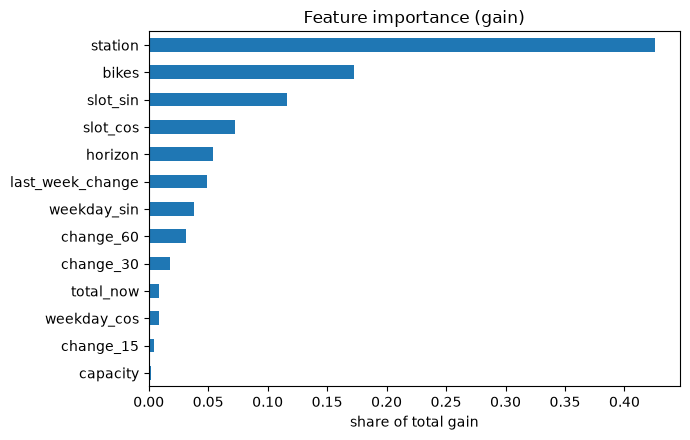

,gain share,splits
station,0.425,9323
bikes,0.173,2209
slot_sin,0.116,2914
slot_cos,0.073,2024
horizon,0.054,1715
last_week_change,0.049,1356
weekday_sin,0.038,1218
change_60,0.031,1276
change_30,0.018,678
total_now,0.009,431


In [2]:
gain = pd.Series(
    booster.feature_importance("gain"), index=booster.feature_name()
).sort_values()
splits = pd.Series(booster.feature_importance("split"), index=booster.feature_name())
share = (gain / gain.sum()).rename("gain share")

fig, ax = plt.subplots(figsize=(7, 4.5))
share.plot.barh(ax=ax, color="tab:blue")
ax.set_xlabel("share of total gain")
ax.set_title("Feature importance (gain)")
fig.tight_layout()
plt.show()

pd.DataFrame({"gain share": share, "splits": splits}).sort_values(
    "gain share", ascending=False
).round(3)

## 2. Error by hour of day

Weekdays only, by local hour at the origin. The model should gain most where
bikes actually move: the morning and afternoon rush.

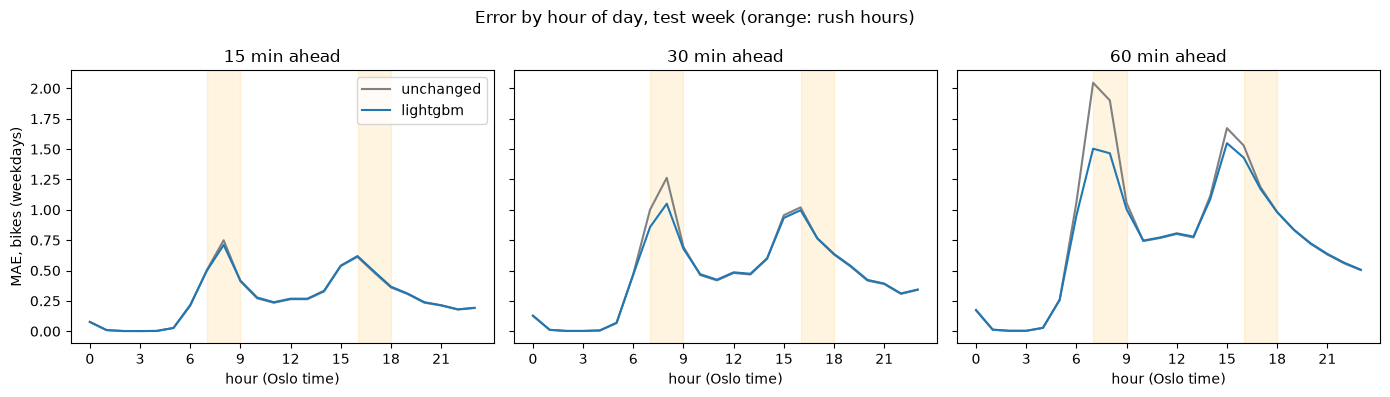

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
gain at 60 min,-0.02,-0.08,-0.22,-0.22,-0.03,-0.01,0.1,0.27,0.23,0.05,...,0.02,0.07,0.07,0.01,0.0,-0.0,-0.01,-0.01,-0.01,-0.01


In [3]:
weekdays = test[test["weekday"] < 5]
by_hour = weekdays.groupby(["horizon", "hour"])[
    ["error_unchanged", "error_lightgbm"]
].mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, horizon in zip(axes, [15, 30, 60], strict=True):
    h = by_hour.loc[horizon]
    ax.plot(h.index, h["error_unchanged"], label="unchanged", color="grey")
    ax.plot(h.index, h["error_lightgbm"], label="lightgbm", color="tab:blue")
    for start, end in [(7, 9), (16, 18)]:
        ax.axvspan(start, end, color="orange", alpha=0.12)
    ax.set_title(f"{horizon} min ahead")
    ax.set_xlabel("hour (Oslo time)")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("MAE, bikes (weekdays)")
axes[0].legend()
fig.suptitle("Error by hour of day, test week (orange: rush hours)")
fig.tight_layout()
plt.show()

gain_60 = 1 - by_hour.loc[60, "error_lightgbm"] / by_hour.loc[60, "error_unchanged"]
gain_60.rename("gain at 60 min").to_frame().T.round(2)

## 3. One station over one day

The station with the largest weekday-rush error for `unchanged` on Tuesday
27 October. Each forecast is drawn at the time it is *for* (the target), so it
can be compared directly with what happened.

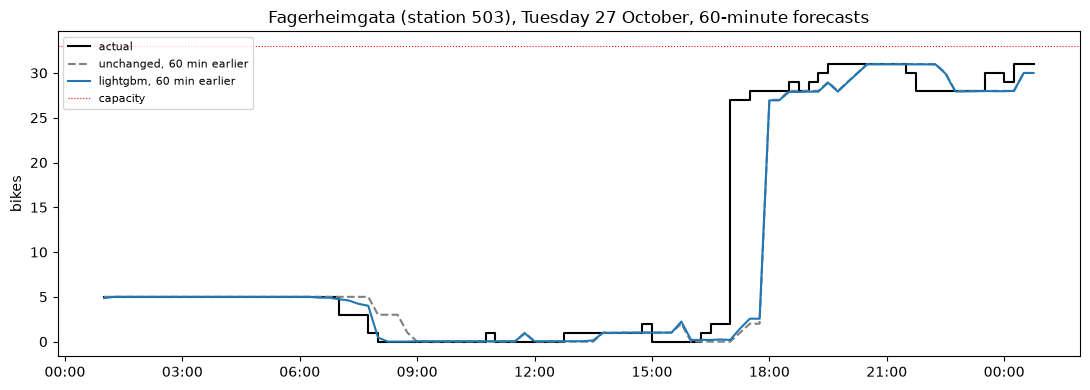

MAE this day, 60 min: unchanged 1.85, lightgbm 1.72


In [4]:
day = pd.Timestamp("2026-10-27", tz=OSLO)
same_day = test[(test["local"] >= day) & (test["local"] < day + pd.Timedelta(days=1))]
rush = same_day[same_day["hour"].isin([7, 8, 16, 17]) & (same_day["horizon"] == 60)]
station = rush.groupby("station_id")["error_unchanged"].mean().idxmax()
name = stations.set_index("station_id").loc[station, "name"]

s = same_day[(same_day["station_id"] == station) & (same_day["horizon"] == 60)]
target_local = s["target_slot"].dt.tz_convert(OSLO)

fig, ax = plt.subplots(figsize=(11, 4))
ax.step(target_local, s["target_bikes"], where="post", color="black", label="actual")
ax.plot(
    target_local,
    s["unchanged"],
    color="grey",
    ls="--",
    label="unchanged, 60 min earlier",
)
ax.plot(target_local, s["lightgbm"], color="tab:blue", label="lightgbm, 60 min earlier")
ax.axhline(s["capacity"].iloc[0], color="red", lw=0.8, ls=":", label="capacity")
ax.set_ylabel("bikes")
ax.set_title(f"{name} (station {station}), Tuesday 27 October, 60-minute forecasts")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=OSLO))
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

print(
    f"MAE this day, 60 min: unchanged {s['error_unchanged'].mean():.2f}, "
    f"lightgbm {s['error_lightgbm'].mean():.2f}"
)

## Findings

- **Station ID carries 43 % of the gain, current bikes 17 % and time of day 19 %
  (sine + cosine).** The model has mostly learned *which station behaves how at
  what time*, plus how full it is now. The recent changes (`change_15/30/60`)
  add only 5 % together, and capacity almost nothing.
- **The gain is concentrated in the morning rush.** At 60 minutes the error at
  07–09 on weekdays drops by about a quarter (07: +27 %, 08: +23 %). The
  afternoon rush improves much less (16: +7 %, 17: +1 %): evening returns are
  spread over more stations and times, so they are harder to predict.
- **At 15 minutes the model and `unchanged` are almost identical.** At night it
  is slightly worse (02–03: −22 %), but those errors are tiny in absolute terms
  (most stations do not change at all).
- **The example station shows both strengths and limits.** In the morning the
  model starts lowering the forecast before the station empties, earlier than
  `unchanged`. At 17:00 the station suddenly gets about 25 bikes, almost
  certainly a redistribution truck. No feature can see that coming, so both
  models are wrong by the same amount for an hour. Truck refills are the
  largest single source of error left.
